## 1. Librerías

In [1]:
#Librerías
import platform
import agentpy as ap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

print("Python", platform.python_version(), "| AgentPy", ap.__version__, "| NumPy", np.__version__,
      "| Pandas", pd.__version__, "| Matplotlib", matplotlib.__version__)

Python 3.13.17 | AgentPy 0.1.5 | NumPy 2.5.5 | Pandas 3.1.1 | Matplotlib 3.11.2


## 2. Parámetros

In [2]:
#Parámetros
from modelo_multiagentes import (ModeloTrafico, ejecutar_experimentos, ESCENARIOS, DT, M, LARGO, V_MAX,
                                 VERDE_FIJO, VERDE_MIN, VERDE_MAX, T_AMARILLO, T_TODO_ROJO,
                                 ESPERA_TOLERADA, TRANSICIONES)

DURACION_S = 300        # segundos simulados por corrida
REPETICIONES = 5        # semillas por escenario y política
SEMILLA = 2026          # la repetición k usa SEMILLA + k en las dos políticas

pd.DataFrame({
    "parámetro": ["escenarios (vehículos)", "paso lógico", "velocidad máxima", "largo del coche",
                  "verde fijo circuito / calle / entrada / glorieta", "verde mínimo / máximo (adaptativo)",
                  "amarillo / todo en rojo", "espera tolerada (adaptativo)"],
    "valor": [str(ESCENARIOS), f"{DT} s", f"{V_MAX / M:.0f} m/s", f"{LARGO / M:.0f} m",
              " / ".join(f"{v:.0f} s" for v in VERDE_FIJO.values()), f"{VERDE_MIN:.0f} s / {VERDE_MAX:.0f} s",
              f"{T_AMARILLO:.0f} s / {T_TODO_ROJO} s", f"{ESPERA_TOLERADA:.0f} s"],
})

,parámetro,valor
0,escenarios (vehículos),"{'ligero': 8, 'moderado': 20, 'elevado': 40}"
1,paso lógico,0.1 s
2,velocidad máxima,12 m/s
3,largo del coche,4 m
4,verde fijo circuito / calle / entrada / glorieta,15 s / 10 s / 10 s / 10 s
5,verde mínimo / máximo (adaptativo),5 s / 25 s
6,amarillo / todo en rojo,3 s / 1.5 s
7,espera tolerada (adaptativo),30 s


## 3. Modelo multiagentes

In [3]:
#Modelo multiagentes
modelo = ModeloTrafico({"n_vehiculos": 20, "politica": "adaptativa", "steps": int(120 / DT)})
salida = modelo.run(seed=SEMILLA, display=False)

print("Agentes:", len(modelo.vehiculos), "AgenteVehiculo,", len(modelo.semaforos), "AgenteSemaforo,",
      len(modelo.intersecciones), "AgenteInterseccion")
print("Segmentos de carril:", len(modelo.red.carriles), "| intersecciones:", list(modelo.inter))
pd.DataFrame([(e, ", ".join(sorted(d))) for e, d in TRANSICIONES.items()],
             columns=["estado del vehículo", "puede pasar a"])

Agentes: 20 AgenteVehiculo, 8 AgenteSemaforo, 8 AgenteInterseccion
Segmentos de carril: 64 | intersecciones: ['TN', 'GN', 'TE', 'GE', 'TS', 'GS', 'TO', 'GO']


,estado del vehículo,puede pasar a
0,AVANZAR,"CAMBIAR_CARRIL, DESACELERAR, ESPERAR, GIRAR"
1,DESACELERAR,"AVANZAR, CAMBIAR_CARRIL, ESPERAR, GIRAR"
2,ESPERAR,"AVANZAR, CAMBIAR_CARRIL, DESACELERAR, GIRAR"
3,GIRAR,"AVANZAR, DESACELERAR, ESPERAR"
4,CAMBIAR_CARRIL,"AVANZAR, DESACELERAR, ESPERAR"


## 4. Simulación

Corrida de prueba: 20 vehículos, control adaptativo, 120 s.

In [4]:
salida.reporters.T.rename(columns={0: "valor"})

,valor
seed,2026.000000
tiempo_espera_promedio_s,8.210000
velocidad_promedio_ms,5.463134
fila_promedio_veh,0.110949
fila_maxima_veh,3.000000
cruces_completados,103.000000
colisiones,0.000000
infracciones_semaforo,0.000000
cambios_carril,35.000000
espera_maxima_continua_s,9.800000


In [5]:
print("Estados al final:", pd.Series([v.estado for v in modelo.vehiculos]).value_counts().to_dict())
pd.Series(modelo.transiciones, name="veces").sort_values(ascending=False).to_frame()

Estados al final: {'AVANZAR': 12, 'DESACELERAR': 5, 'GIRAR': 2, 'ESPERAR': 1}


,veces
AVANZAR->DESACELERAR,195
GIRAR->AVANZAR,126
DESACELERAR->GIRAR,121
DESACELERAR->AVANZAR,57
DESACELERAR->ESPERAR,41
ESPERAR->AVANZAR,38
AVANZAR->CAMBIAR_CARRIL,34
CAMBIAR_CARRIL->AVANZAR,29
AVANZAR->GIRAR,29
GIRAR->DESACELERAR,24


In [6]:
# Negociación de un vehículo con una intersección (solo cuando cambia la respuesta)
msgs = pd.DataFrame(modelo.registro_mensajes)
rechazados = msgs.loc[msgs["tipo"] == "RECHAZO", "para"]
veh = rechazados[rechazados.isin(msgs.loc[msgs["tipo"] == "PERMISO", "para"])].iloc[0]
ejemplo = msgs[((msgs["de"] == veh) | (msgs["para"] == veh)) & (msgs["tipo"] != "SOLICITA")]
print({k: modelo.contadores[k] for k in ["SOLICITA", "PERMISO", "RECHAZO", "REVOCA", "CANCELA", "LIBERA"]})
ejemplo[ejemplo["detalle"].ne(ejemplo["detalle"].shift()) | ejemplo["tipo"].ne(ejemplo["tipo"].shift())].head(10)

{'SOLICITA': 3915, 'PERMISO': 114, 'RECHAZO': 3801, 'REVOCA': 2, 'CANCELA': 4, 'LIBERA': 103}


,t,de,para,tipo,detalle
7,0.1,TS,17,PERMISO,S_int_x
10,0.1,17,TS,CANCELA,S_int_x
18,0.2,TS,17,RECHAZO,S_ext_x: sin espacio a la salida
48,0.5,TS,17,PERMISO,S_ext_x


## 5. Experimentos

3 escenarios × 2 políticas × 5 repeticiones.

In [7]:
resultados, series = ejecutar_experimentos(ESCENARIOS, ("fija", "adaptativa"), REPETICIONES, DURACION_S, SEMILLA)
Path("results").mkdir(exist_ok=True)
resultados.to_csv("results/resultados_experimentos.csv", index=False)
print(len(resultados), "corridas -> results/resultados_experimentos.csv")

30 corridas -> results/resultados_experimentos.csv


## 6. Resultados

In [8]:
metricas = ["tiempo_espera_promedio_s", "velocidad_promedio_ms", "fila_promedio_veh", "fila_maxima_veh",
            "cruces_completados", "colisiones", "infracciones_semaforo"]
orden = list(ESCENARIOS)
resumen = (resultados.groupby(["escenario", "politica"])[metricas].agg(["mean", "std"])
           .reindex(orden, level=0).round(2))
resumen.to_csv("results/resumen_experimentos.csv")
resumen

tiempo_espera_promedio_s       velocidad_promedio_ms  \
                                         mean   std                  mean   
escenario politica                                                          
ligero    adaptativa                     8.69  1.75                  6.41   
          fija                          69.38  4.87                  4.42   
moderado  adaptativa                    19.96  1.99                  5.67   
          fija                          65.47  1.16                  4.40   
elevado   adaptativa                    40.85  1.79                  4.84   
          fija                          67.89  4.45                  4.04   

                           fila_promedio_veh       fila_maxima_veh        \
                       std              mean   std            mean   std   
escenario politica                                                         
ligero    adaptativa  0.09              0.02  0.00             2.2  0.45   
          fija        0.09              0.15  0.01             3.2  0.84   
moderado  adaptativa  0.07              0.11  0.01             4.6  1.14   
          fija        0.05              0.36  0.01             5.0  0.71   
elevado   adaptativa  0.11              0.45  0.02             8.4  1.52   
          fija        0.14              0.75  0.05             9.0  1.00   

                     cruces_completados        colisiones       \
                                   mean    std       mean  std   
escenario politica                                               
ligero    adaptativa              122.2   1.92        0.0  0.0   
          fija                     84.4   2.88        0.0  0.0   
moderado  adaptativa              269.0   4.47        0.0  0.0   
          fija                    204.0   2.65        0.0  0.0   
elevado   adaptativa              450.4   7.50        0.0  0.0   
          fija                    371.8  11.19        0.0  0.0   

                     infracciones_semaforo       
                                      mean  std  
escenario politica                               
ligero    adaptativa                   0.0  0.0  
          fija                         0.0  0.0  
moderado  adaptativa                   0.0  0.0  
          fija                         0.0  0.0  
elevado   adaptativa                   0.0  0.0  
          fija                         0.0  0.0

In [9]:
# Diferencia del control adaptativo respecto al fijo [%] (negativo = menor con adaptativo)
medias = resultados.groupby(["escenario", "politica"])[metricas[:5]].mean()
fija = medias.xs("fija", level="politica")
adaptativa = medias.xs("adaptativa", level="politica")
print("Colisiones totales:", int(resultados["colisiones"].sum()),
      "| infracciones totales:", int(resultados["infracciones_semaforo"].sum()),
      "| mayor espera continua [s]:", round(resultados["espera_maxima_continua_s"].max(), 1))
((adaptativa - fija) / fija * 100).reindex(orden).round(1)

Colisiones totales: 0 | infracciones totales: 0 | mayor espera continua [s]: 41.1


,tiempo_espera_promedio_s,velocidad_promedio_ms,fila_promedio_veh,fila_maxima_veh,cruces_completados
escenario,,,,,
ligero,-87.5,44.9,-87.8,-31.2,44.8
moderado,-69.5,28.8,-70.1,-8.0,31.9
elevado,-39.8,20.0,-40.2,-6.7,21.1


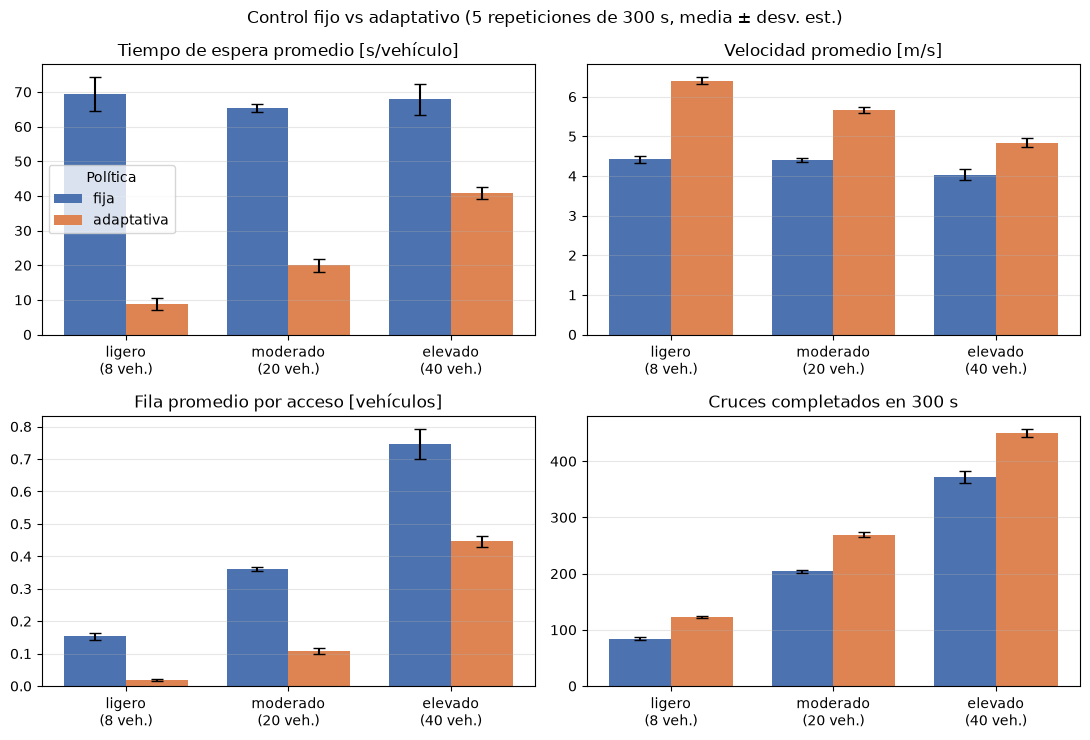

In [10]:
colores = {"fija": "#4C72B0", "adaptativa": "#DD8452"}
fig, ejes = plt.subplots(2, 2, figsize=(11, 7.5))
graficas = [("tiempo_espera_promedio_s", "Tiempo de espera promedio [s/vehículo]"),
            ("velocidad_promedio_ms", "Velocidad promedio [m/s]"),
            ("fila_promedio_veh", "Fila promedio por acceso [vehículos]"),
            ("cruces_completados", f"Cruces completados en {DURACION_S} s")]
x = np.arange(len(orden))
for eje, (col, titulo) in zip(ejes.flat, graficas):
    for k, pol in enumerate(["fija", "adaptativa"]):
        datos = resultados[resultados.politica == pol].groupby("escenario")[col]
        eje.bar(x + (k - 0.5) * 0.38, datos.mean().reindex(orden), 0.38, yerr=datos.std().reindex(orden),
                capsize=4, label=pol, color=colores[pol])
    eje.set_xticks(x, [f"{e}\n({ESCENARIOS[e]} veh.)" for e in orden])
    eje.set_title(titulo)
    eje.grid(axis="y", alpha=0.3)
ejes[0, 0].legend(title="Política")
fig.suptitle(f"Control fijo vs adaptativo ({REPETICIONES} repeticiones de {DURACION_S} s, media ± desv. est.)")
fig.tight_layout()
fig.savefig("results/comparacion_politicas.png", dpi=130)
plt.show()

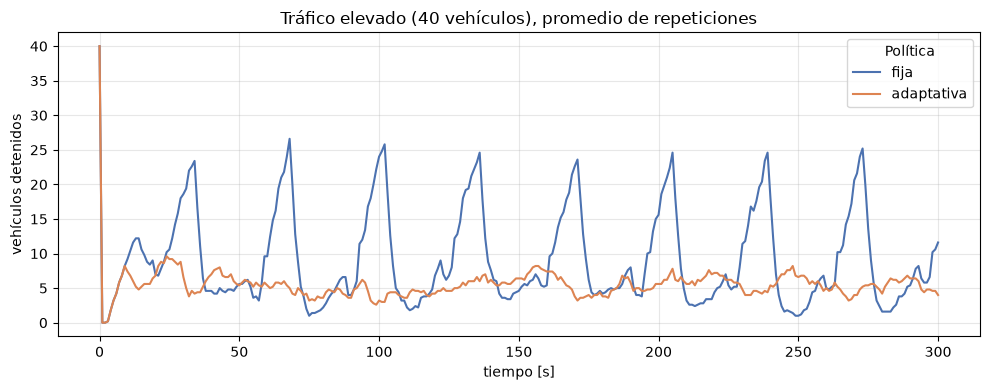

In [11]:
fig, eje = plt.subplots(figsize=(10, 4))
elevado = series[series.escenario == "elevado"]
for pol in ["fija", "adaptativa"]:
    curva = elevado[elevado.politica == pol].groupby("t")["vehiculos_detenidos"].mean()
    eje.plot(curva.index * DT, curva.values, label=pol, color=colores[pol])
eje.set_xlabel("tiempo [s]")
eje.set_ylabel("vehículos detenidos")
eje.set_title(f"Tráfico elevado ({ESCENARIOS['elevado']} vehículos), promedio de repeticiones")
eje.legend(title="Política")
eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("results/detenidos_trafico_elevado.png", dpi=130)
plt.show()

**Notas.** Con estas semillas el control adaptativo tuvo menor espera, filas más cortas, mayor velocidad
y más cruces en los tres escenarios; la ventaja disminuye al aumentar el tráfico. Los tiempos del control
fijo se eligieron a mano (sin optimizar). El análisis completo va en el reporte.